## Segundo paso: análisar los dataset .csv de (AAEC, ArGPT, MTC, AASS)

In [249]:
import pandas as pd
from tabulate import tabulate
import networkx as nx
import matplotlib.pyplot as plt
from networkx.drawing.nx_pydot import graphviz_layout
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [197]:
result_path = "./results/minimal_v5/"

In [250]:
def di_graph(text_id, G):

    pos = graphviz_layout(G, prog="dot")

    plt.figure(figsize=(14, 10))
    
    # Separar aristas por tipo de relación
    edges_support = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "support"]

    edges_attack = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "attack"]


    # Separar nodos por tipo y asignar color
    nodes_premise     = [n for n, d in G.nodes(data=True) if d.get("component") == "Premise"]
    nodes_majorclaim  = [n for n, d in G.nodes(data=True) if d.get("component") == "MajorClaim"]
    nodes_other       = [n for n in G.nodes() if n not in nodes_premise and n not in nodes_majorclaim]

    # Dibujar nodos por grupo
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_premise,    node_color="lightgreen", node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_majorclaim, node_color="orange",     node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_other,      node_color="lightblue",  node_size=1500)


    # Dibujar etiquetas de nodos
    labels = {n: n.split("_")[-1] for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=9)

    # Dibujar aristas con flechas visibles
    nx.draw_networkx_edges(G, pos, edgelist=edges_support,
                           edge_color="blue",
                           arrows=True,
                           arrowsize=20,
                           arrowstyle="-|>",
                           connectionstyle="arc3,rad=0.1",
                           min_source_margin=15,
                           min_target_margin=15)

    nx.draw_networkx_edges(G, pos, edgelist=edges_attack,
                           edge_color="red",
                           arrows=True,
                           arrowsize=20,
                           arrowstyle="-|>",
                           connectionstyle="arc3,rad=0.1",
                           min_source_margin=15,
                           min_target_margin=15)

    # Mostrar etiquetas de aristas
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                                font_size=9, rotate=False)

    # Leyenda
    legend = [
        Patch(color="lightgreen", label="Premise"),
        Patch(color="orange",     label="MajorClaim"),
        Patch(color="lightblue",  label="Other"),
    ]
    plt.legend(handles=legend, loc="upper left")
    
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [251]:
def plot_grafo(text_id, G):
    # Cor por nó
    color_nodo = {
        "MajorClaim" : "#e74c3c",   # Vermelho
        "Claim"      : "#3498db",   # Azul
        "Premise"    : "#2ecc71",   # Verde
    }
    node_colors = [
        color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
        for n in G.nodes()
    ]

    colores_label = {
        "support" : "#27ae60",   # Verde oscuro
        "attack"  : "#c0392b",   # Vermelho oscuro
    }
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=30, iterations=100)
    
    # Etiquetas de nodos con ID + tipo de componente
    node_labels = {
        n: f"{n}\n{G.nodes[n].get('component', '')}"
        for n in G.nodes()
    }

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="support"),
        Line2D([0], [0], color="red",   linewidth=2, label="attack"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Dataset

In [ ]:
# Cargar el DataFrame
df_cdcp = pd.read_pickle(result_path + "CDCP_Minimal_Grafo.pkl")
df_aaec = pd.read_pickle(result_path + "AAEC_Minimal_Grafo.pkl")
df_argpt = pd.read_pickle(result_path + "ArGPT_Minimal_Grafo.pkl")
df_mtc = pd.read_pickle(result_path + "MTC_Minimal_Grafo.pkl")
df_aasd = pd.read_pickle(result_path + "AASD_Minimal_Grafo.pkl")

In [253]:
df = df_cdcp
df

,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
0,CDCP_00194,3,minimalist_labels labels_relation source...,"(CDCP_00194_0, CDCP_00194_1, CDCP_00194_2)",3,1,1,2,2,True,False,False,False,True
1,CDCP_00195,3,minimalist_labels labels_relation source...,"(CDCP_00195_0, CDCP_00195_1, CDCP_00195_2)",3,2,0,1,1,True,True,True,True,True
2,CDCP_00196,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00196_0, CDCP_00196_1, CDCP_00196_2, CDC...",5,0,5,5,5,True,False,False,False,True
3,CDCP_00197,4,minimalist_labels labels_relation source...,"(CDCP_00197_0, CDCP_00197_1, CDCP_00197_2, CDC...",4,1,2,3,3,True,False,False,False,True
4,CDCP_00198,4,minimalist_labels labels_relation source...,"(CDCP_00198_0, CDCP_00198_1, CDCP_00198_2, CDC...",4,1,2,3,3,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,CDCP_01411,15,minimalist_labels labels_relation sourc...,"(CDCP_01411_0, CDCP_01411_1, CDCP_01411_2, CDC...",15,8,3,7,10,True,False,False,False,True
726,CDCP_01412,15,minimalist_labels labels_relation sourc...,"(CDCP_01412_0, CDCP_01412_1, CDCP_01412_2, CDC...",15,7,5,8,8,True,False,False,False,True
727,CDCP_01414,12,minimalist_labels labels_relation source...,"(CDCP_01414_0, CDCP_01414_1, CDCP_01414_2, CDC...",12,2,8,10,10,True,False,False,False,True
728,CDCP_01417,18,minimalist_labels labels_relation sourc...,"(CDCP_01417_0, CDCP_01417_1, CDCP_01417_2, CDC...",18,4,11,14,14,True,False,False,False,True


### Caracteristicas de grafo

In [294]:
# Numeros de nodos y componentes
label_columna = "n_edges"
df_comparacion = df[
    (df[label_columna] == 0) 
    # &
    # (df["is_connected"] == True)
    # &
    # (df["is_arborescence"] == True)
]
conteo = df_comparacion.groupby(label_columna).size()
lista = conteo.to_dict()
print(df_comparacion.shape)
print("Lista de componentes: ",lista)
df_comparacion

(206, 14)
Lista de componentes:  {0: 206}


,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
2,CDCP_00196,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00196_0, CDCP_00196_1, CDCP_00196_2, CDC...",5,0,5,5,5,True,False,False,False,True
5,CDCP_00199,2,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00199_0, CDCP_00199_1)",2,0,2,2,2,True,False,False,False,True
11,CDCP_00206,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00206_0, CDCP_00206_1, CDCP_00206_2, CDC...",5,0,5,5,5,True,False,False,False,True
17,CDCP_00218,2,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00218_0, CDCP_00218_1)",2,0,2,2,2,True,False,False,False,True
22,CDCP_00225,2,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00225_0, CDCP_00225_1)",2,0,2,2,2,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
711,CDCP_01389,11,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_01389_0, CDCP_01389_1, CDCP_01389_2, CDC...",11,0,11,11,11,True,False,False,False,True
713,CDCP_01394,2,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_01394_0, CDCP_01394_1)",2,0,2,2,2,True,False,False,False,True
714,CDCP_01395,3,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_01395_0, CDCP_01395_1, CDCP_01395_2)",3,0,3,3,3,True,False,False,False,True
718,CDCP_01401,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_01401_0, CDCP_01401_1, CDCP_01401_2, CDC...",5,0,5,5,5,True,False,False,False,True


In [295]:
id_text_busca = "CDCP_01389"
columna = "text_id"
result = df[df[columna] == id_text_busca]
result_info = result.iloc[0]

In [296]:
result

,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
711,CDCP_01389,11,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_01389_0, CDCP_01389_1, CDCP_01389_2, CDC...",11,0,11,11,11,True,False,False,False,True


In [297]:
result_info["info"]

,minimalist_labels,labels_relation,source_id,label_component_source,minimal_label_component_source,target_id,label_component_target,minimal_label_component_target


/tmp/ipykernel_10443/2138295617.py:3: DeprecationWarning: nx.nx_pydot.graphviz_layout depends on the pydot package, which has known issues and is not actively maintained. Consider using nx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723
  pos = graphviz_layout(G, prog="dot")


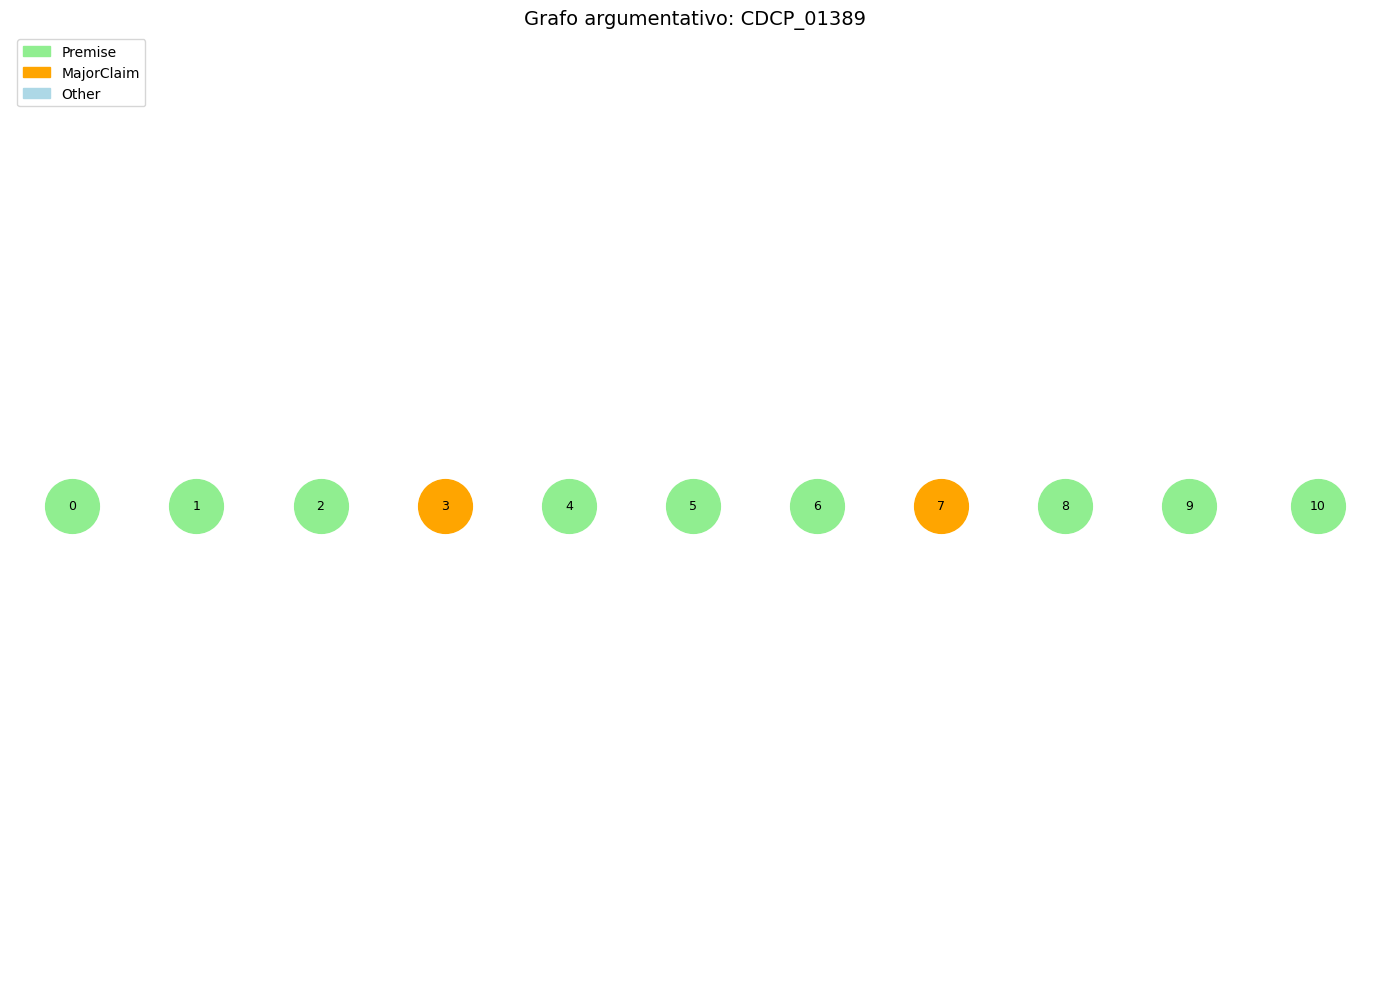

In [298]:
# plot_grafo(id_text_busca, result_info["graph"])
di_graph(id_text_busca, result_info["graph"])

## Estadisticas

In [292]:
def plot_estadisticas(df):
    bool_cols = ["is_acyclic", "is_connected", "is_tree", "is_arborescence", "is_forest"]
    num_cols  = ["n_nodes", "n_edges", "n_isolates", "n_comp", "n_root"]

    # Convertir a numérico
    df[num_cols] = df[num_cols].astype(int)
    # Convertir columnas booleanas a bool
    df[bool_cols] = df[bool_cols].astype(bool)

    resultado = (df[bool_cols].mean() * 100).round(2).reset_index()
    resultado.columns = ["Propiedad", "% True"]
    resultado["% True"] = resultado["% True"].astype(str)

    # Estadísticas
    print("=== Estadísticas ===")
    print(tabulate(df[num_cols].describe(), headers='keys', tablefmt='rounded_outline', showindex=True))
    print(tabulate(resultado, headers='keys', tablefmt='rounded_outline', showindex=False))

    # # Gráficos
    # fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # # 1. Distribución nodos
    # df["n_nodes"].hist(ax=axes[0,0], bins=20, color="steelblue")
    # axes[0,0].set_title("Distribución de Nodos")

    # # 2. Distribución aristas
    # df["n_edges"].hist(ax=axes[0,1], bins=20, color="orange")
    # axes[0,1].set_title("Distribución de Aristas")

    # # 3. Propiedades booleanas
    # df[bool_cols].sum().plot(kind="bar", ax=axes[1,0], color="steelblue")
    # axes[1,0].set_title("Grafos que cumplen cada propiedad")
    # axes[1,0].tick_params(axis='x', rotation=45)

    # # 4. Nodos vs Aristas
    # axes[1,1].scatter(df["n_nodes"], df["n_edges"], alpha=0.5, color="steelblue")
    # axes[1,1].set_title("Nodos vs Aristas")
    # axes[1,1].set_xlabel("n_nodes")
    # axes[1,1].set_ylabel("n_edges")

    # plt.tight_layout()
    # plt.show()

In [291]:
plot_estadisticas(df_comparacion)

=== Estadísticas ===
╭───────┬───────────┬───────────┬──────────────┬───────────┬───────────╮
│       │   n_nodes │   n_edges │   n_isolates │    n_comp │    n_root │
├───────┼───────────┼───────────┼──────────────┼───────────┼───────────┤
│ count │ 730       │ 730       │    730       │ 730       │ 730       │
│ mean  │   6.74932 │   1.94932 │      3.77671 │   4.89315 │   4.97945 │
│ std   │   4.89101 │   2.11505 │      3.7392  │   4.10321 │   4.10104 │
│ min   │   2       │   0       │      0       │   1       │   1       │
│ 25%   │   3       │   0       │      1       │   2       │   2       │
│ 50%   │   5       │   1       │      3       │   4       │   4       │
│ 75%   │   9       │   3       │      5       │   6.75    │   7       │
│ max   │  34       │  16       │     22       │  27       │  27       │
╰───────┴───────────┴───────────┴──────────────┴───────────┴───────────╯
╭─────────────────┬──────────╮
│ Propiedad       │   % True │
├─────────────────┼──────────┤
│ is_acycl